## 1. Импорты, параметры и классы

In [1]:
import os, time, random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

path_to_folder = './data'
IMAGE_SIZE     = 45
MAX_PER_CLASS  = 20000
K_VALUES       = [1, 3, 5, 7, 9, 11, 15]
RANDOM_STATE   = 42

name_folders = [x[0].split('\\')[-1] for x in os.walk(path_to_folder)][1:]
NUM_CLASSES = len(name_folders)
print(f"Классов: {NUM_CLASSES}\n{name_folders}")

Классов: 21
['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'h', 't', 'times', 'w', 'X', 'y']


## 2. Загрузка датасета

In [2]:
def _load_one(args):
    path, label = args
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    img = cv2.bitwise_not(img)
    return img.flatten(), label

tasks = []
rng = random.Random(RANDOM_STATE)
for class_idx, sym in enumerate(name_folders):
    folder = os.path.join(path_to_folder, sym)
    files = os.listdir(folder)
    rng.shuffle(files)
    for f in files[:MAX_PER_CLASS]:
        tasks.append((os.path.join(folder, f), class_idx))

print(f"Загрузка {len(tasks)} изображений...")
t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    results = list(ex.map(_load_one, tasks))
results = [r for r in results if r is not None]

X = np.array([r[0] for r in results], dtype=np.float32) / 255.0
y = np.array([r[1] for r in results], dtype=np.int32)

print(f"Готово за {time.time()-t0:.1f} с")
print(f"X: {X.shape}, y: {y.shape}, классов: {len(np.unique(y))}")

Загрузка 186927 изображений...
Готово за 43.3 с
X: (186927, 2025), y: (186927,), классов: 21


## 3. train/test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True,
    stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (149541, 2025), Test: (37386, 2025)


## 4. Перебор K


=== k = 1 ===
  accuracy = 0.9761    (199.4 с)

=== k = 3 ===
  accuracy = 0.8810    (198.3 с)

=== k = 5 ===
  accuracy = 0.7450    (218.6 с)

=== k = 7 ===
  accuracy = 0.6998    (241.2 с)

=== k = 9 ===
  accuracy = 0.6657    (188.3 с)

=== k = 11 ===
  accuracy = 0.6265    (246.7 с)

=== k = 15 ===
  accuracy = 0.5669    (230.3 с)


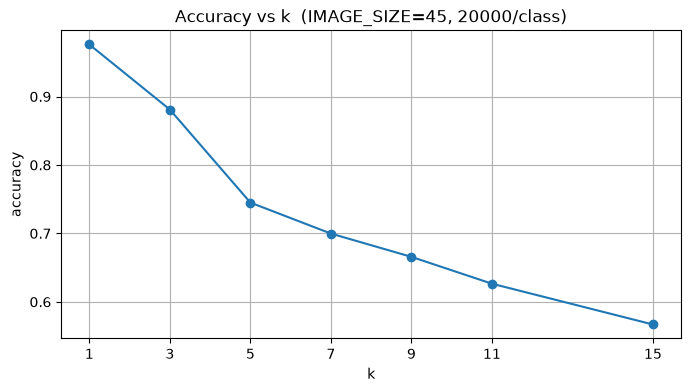

k= 1  acc=0.9761  time=199.4 с
k= 3  acc=0.8810  time=198.3 с
k= 5  acc=0.7450  time=218.6 с
k= 7  acc=0.6998  time=241.2 с
k= 9  acc=0.6657  time=188.3 с
k=11  acc=0.6265  time=246.7 с
k=15  acc=0.5669  time=230.3 с

>>> Оптимальное k = 1  (accuracy = 0.9761)


In [4]:
accuracies = []
times = []
for k in K_VALUES:
    print(f"\n=== k = {k} ===")
    t0 = time.time()
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1, algorithm='brute')
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    times.append(time.time() - t0)
    print(f"  accuracy = {acc:.4f}    ({time.time()-t0:.1f} с)")

plt.figure(figsize=(8, 4))
plt.plot(K_VALUES, accuracies, marker='o')
plt.xlabel('k'); plt.ylabel('accuracy')
plt.grid(True); plt.xticks(K_VALUES)
plt.title(f'Accuracy vs k  (IMAGE_SIZE={IMAGE_SIZE}, {MAX_PER_CLASS}/class)')
plt.show()

for k, a, t in zip(K_VALUES, accuracies, times):
    print(f"k={k:2d}  acc={a:.4f}  time={t:.1f} с")

best_k = K_VALUES[int(np.argmax(accuracies))]
print(f"\n>>> Оптимальное k = {best_k}  (accuracy = {max(accuracies):.4f})")

## 5. Финальная модель

In [5]:
print(f"Финальная модель k={best_k}, fit на полном train...")
best_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1, algorithm='brute')
t0 = time.time()
best_knn.fit(X_train, y_train)
print(f"  fit: {time.time()-t0:.1f} с")

print("Predict на полном тесте для отчёта...")
t0 = time.time()
y_pred = best_knn.predict(X_test)
print(f"  predict: {time.time()-t0:.1f} с")
print(f"  accuracy = {accuracy_score(y_test, y_pred):.4f}\n")

print("classification_report:")
print(classification_report(y_test, y_pred,
                            target_names=name_folders,
                            digits=3, zero_division=0))

Финальная модель k=1, fit на полном train...
  fit: 0.1 с
Predict на полном тесте для отчёта...
  predict: 187.8 с
  accuracy = 0.9761

classification_report:
              precision    recall  f1-score   support

           (      0.962     0.997     0.979      2859
           )      0.952     0.999     0.975      2871
           +      0.997     0.950     0.973      4000
           ,      0.673     0.929     0.781       381
           -      0.964     1.000     0.982      4000
           0      0.999     0.996     0.997      1383
           1      0.952     0.973     0.962      4000
           2      0.993     0.958     0.975      4000
           3      0.994     0.990     0.992      2182
           4      0.998     0.976     0.987      1479
           5      0.994     0.973     0.984       709
           6      1.000     0.981     0.990       624
           7      0.979     0.985     0.982       582
           8      1.000     0.980     0.990       614
           9      1.000     0.

## 6. Генератор + распознавание

In [6]:
def generate_sequence_image(text, img_size=IMAGE_SIZE):
    images = []
    for char in text:
        if char == ' ':
            images.append(np.zeros((img_size, img_size), dtype=np.uint8))
            continue
        
        actual_char = 'times' if char == '*' else char
        folder = os.path.join(path_to_folder, actual_char)
        if not os.path.exists(folder):
            continue
        
        files = os.listdir(folder)
        if not files:
            continue

        img = cv2.imread(os.path.join(folder, random.choice(files)), cv2.IMREAD_GRAYSCALE)
        img = cv2.bitwise_not(img)
        
        if len(images) > 0:
            images.append(np.zeros((img_size, 15), dtype=np.uint8))
            
        images.append(img)

    if not images:
        return None
    result = np.hstack(images)
    return cv2.copyMakeBorder(result, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=0)


def recognize(text):
    test_img = generate_sequence_image(text)
    if test_img is None:
        return None

    _, thresh = cv2.threshold(test_img, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    bboxes = sorted([cv2.boundingRect(c) for c in contours], key=lambda b: b[0])

    recognized = ""
    vis = cv2.cvtColor(test_img, cv2.COLOR_GRAY2RGB)

    for (x, y_, w, h) in bboxes:
        if w * h < 50: 
            continue
            
        cx = x + w // 2
        cy = y_ + h // 2
        half = IMAGE_SIZE // 2

        x1 = cx - half
        y1 = cy - half
        x2 = x1 + IMAGE_SIZE
        y2 = y1 + IMAGE_SIZE
        
        pad_top = max(0, -y1)
        pad_bottom = max(0, y2 - test_img.shape[0])
        pad_left = max(0, -x1)
        pad_right = max(0, x2 - test_img.shape[1])
        
        roi = test_img[max(0, y1):min(test_img.shape[0], y2), 
                       max(0, x1):min(test_img.shape[1], x2)]
                       
        if pad_top or pad_bottom or pad_left or pad_right:
            roi = cv2.copyMakeBorder(roi, pad_top, pad_bottom, pad_left, pad_right, 
                                     cv2.BORDER_CONSTANT, value=0)
        
        vec = roi.flatten().reshape(1, -1).astype(np.float32) / 255.0
        idx = int(best_knn.predict(vec)[0])
        pred_char = name_folders[idx]
        
        display_char = '*' if pred_char == 'times' else pred_char
        recognized += display_char
        
        cv2.rectangle(vis, (x, y_), (x+w, y_+h), (255, 0, 0), 2)
        cv2.putText(vis, display_char, (x, max(y_-6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 200, 0), 2)

    plt.figure(figsize=(max(8, len(text)*1.2), 3))
    plt.imshow(vis); plt.axis('off'); plt.tight_layout(); plt.show()
    print(f"{text!r} → {recognized!r}\n")
    return recognized

## 7. Прогон строк

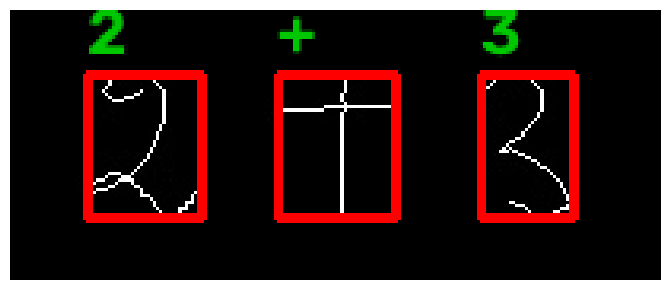

'2+3' → '2+3'



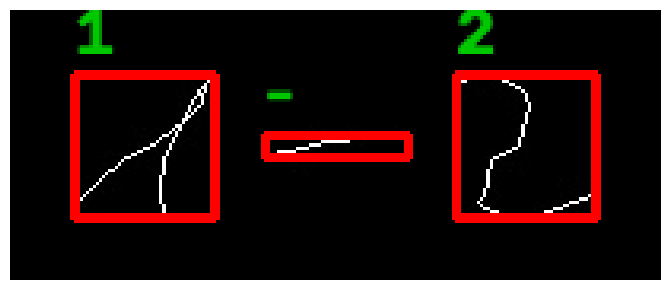

'1-2' → '1-2'



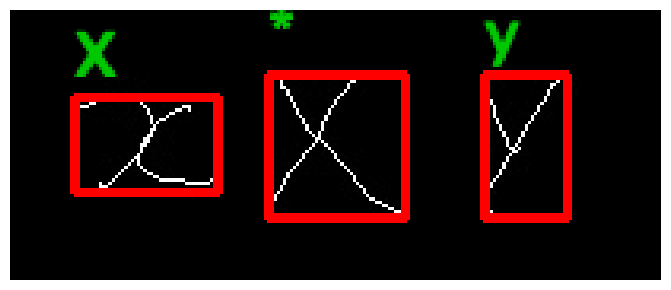

'X*y' → 'X*y'



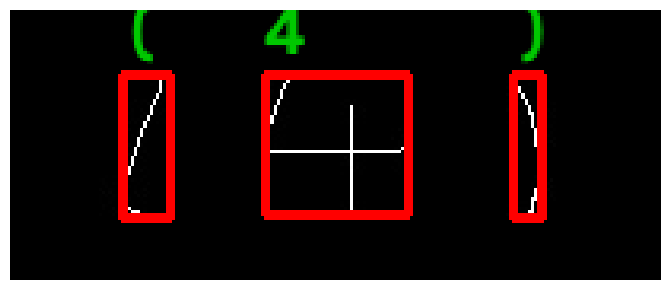

'(4)' → '(4)'



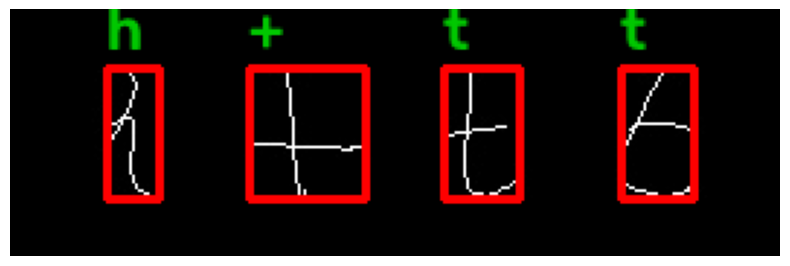

'h+tt' → 'h+tt'

ИТОГ:
  V  '2+3'      → '2+3'
  V  '1-2'      → '1-2'
  V  'X*y'      → 'X*y'
  V  '(4)'      → '(4)'
  V  'h+tt'     → 'h+tt'

Точность: 5/5


In [7]:
test_strings = ["2+3", "1-2", "X*y", "(4)", "h+tt"]
results = [(s, recognize(s)) for s in test_strings]

print("ИТОГ:")
for s, r in results:
    print(f"  {'V' if s == r else 'X'}  {s!r:10s} → {r!r}")
print(f"\nТочность: {sum(s==r for s,r in results)}/{len(results)}")